# Projeto gmxflow

Este notebook conduz uma simulação de proteína sem ligante. A configuração científica continua em `project.toml`; revise o campo de força e os parâmetros antes de executar. O projeto remove resíduos `HOH` durante a preparação e preserva o PDB original em `inputs/`.

A API Python usada aqui ainda é experimental. A execução pode consumir bastante tempo e recursos computacionais, dependendo da configuração. Se `simulation.profile = "smoke"`, os resultados servem apenas para verificar a integração do software e não têm interpretação científica.

## 1. Abrir o projeto

Coloque os arquivos de entrada na pasta `inputs/` e ajuste os caminhos correspondentes em `project.toml`.

In [3]:
from gmxflow.api import GmxFlowProject

project = GmxFlowProject.open('project.toml')
project.edit_config()
print('Projeto aberto.')

Projeto aberto.


## 2.1 Parametrização

In [4]:
project.edit_config()

## 2. Verificar se está tudo pronto

Esta verificação confere os arquivos, o GROMACS e o campo de força. Ela não inicia a simulação.

In [1]:
project.validate()
print('Pré-requisitos verificados.')

NameError: name 'project' is not defined

## 3. Executar a simulação

> Antes de executar, confira os parâmetros em `project.toml` e os arquivos em `inputs/`. Esta célula inicia a pipeline completa definida para o projeto.

In [3]:
execution_report = project.run()
project.show_execution(execution_report)

### Resumo da execução

,Etapa,Status,Duração (s),Log
0,workspace,concluída,0.000,/home/michel/Devel/gmxflow/examples/lysozyme_in_water/work/logs/00_workspace.log
1,prepare,reutilizada (sem alterações),0.000,/home/michel/Devel/gmxflow/examples/lysozyme_in_water/work/logs/01_prepare.log
2,topology,concluída,0.048,/home/michel/Devel/gmxflow/examples/lysozyme_in_water/work/logs/02_topology.log
3,box,concluída,0.011,/home/michel/Devel/gmxflow/examples/lysozyme_in_water/work/logs/03_box.log
4,solvate,concluída,0.324,/home/michel/Devel/gmxflow/examples/lysozyme_in_water/work/logs/04_solvate.log
5,ions-grompp,concluída,0.064,/home/michel/Devel/gmxflow/examples/lysozyme_in_water/work/logs/05_ions-grompp.log
6,ions,concluída,0.033,/home/michel/Devel/gmxflow/examples/lysozyme_in_water/work/logs/06_ions.log
7,em-grompp,concluída,0.068,/home/michel/Devel/gmxflow/examples/lysozyme_in_water/work/logs/07_em-grompp.log
8,em,concluída,12.634,/home/michel/Devel/gmxflow/examples/lysozyme_in_water/work/logs/08_em.log
9,nvt-grompp,concluída,0.229,/home/michel/Devel/gmxflow/examples/lysozyme_in_water/work/logs/09_nvt-grompp.log


## 4. Abrir o relatório

O relatório será exibido aqui. A versão HTML para compartilhar também fica disponível em `outputs/report.html`.

# lysozyme_in_water

Lisozima em água, baseada no tutorial introdutório do GROMACS

## Resumo

,Item,Valor
0,Perfil,smoke
1,Passos de produção,10
2,RMSD backbone médio,0.005 +/- 0.002 nm


### Avisos
- Perfil smoke: resultados servem apenas para validar a pipeline, não para interpretação científica.

## Execução

... (2 outputs left out)

## Análises

,Métrica,Média,Desvio padrão,Mínimo,Máximo,Pontos,Fração > 0,Unidade
0,RMSD do backbone,0.004651,0.002348,0.000499,0.007625,11,None,nm
1,RMSF por resíduo,0.002941,0.000612,0.001700,0.004600,129,None,nm
2,Raio de giro,1.399461,0.000038,1.399405,1.399521,11,None,nm


## Gráficos

### Rmsd Bb

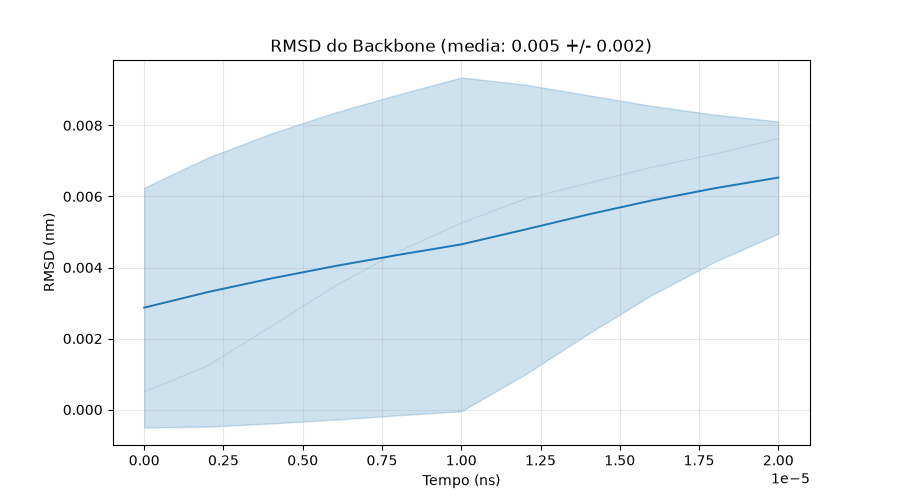

### Rmsf

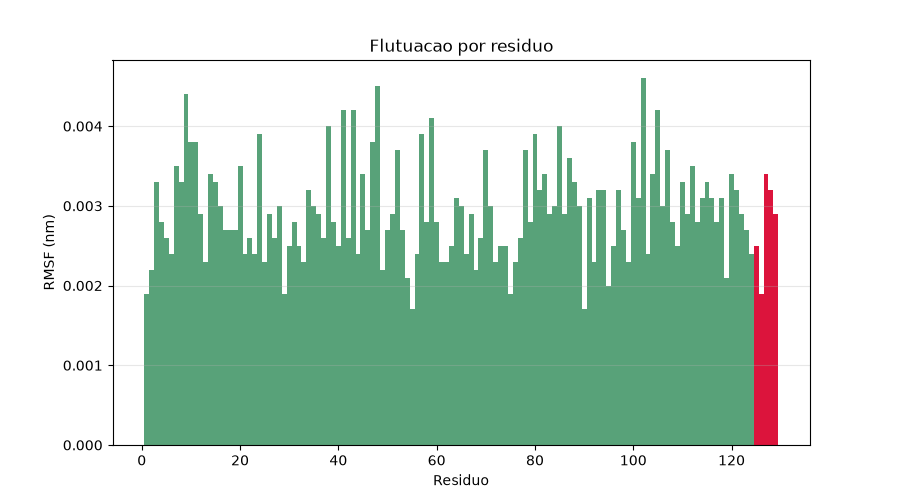

### Rg

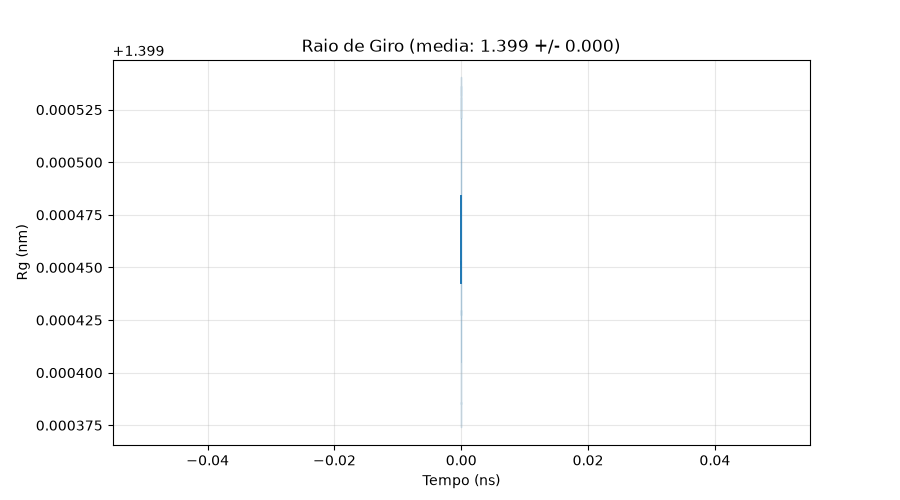

Relatório distribuível: `outputs/report.html`

In [4]:
project.show_report()